In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    "../data/ecommerce_sales_cleaned.csv",
    parse_dates=["order_date"]
)

sns.set_theme(style="whitegrid")

In [2]:
df.describe()

,order_id,order_date,customer_id,quantity,unit_price,discount,delivery_days,customer_rating,revenue
count,5000.000000,5000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,12500.500000,2028-11-04 12:00:00,1505.701200,4.044800,308.418774,0.179984,6.118800,2.973980,1021.955148
min,10001.000000,2022-01-01 00:00:00,1000.000000,1.000000,15.150000,0.000000,1.000000,1.000000,11.210000
25%,11250.750000,2025-06-03 18:00:00,1253.000000,2.000000,161.895000,0.090000,3.000000,2.000000,354.527500
50%,12500.500000,2028-11-04 12:00:00,1510.000000,4.000000,309.890000,0.180000,6.000000,3.000000,796.650000
75%,13750.250000,2032-04-07 06:00:00,1761.000000,6.000000,455.557500,0.270000,9.000000,4.000000,1515.690000
max,15000.000000,2035-09-09 00:00:00,1999.000000,7.000000,599.960000,0.350000,11.000000,5.000000,4119.330000
std,1443.520003,NaN,290.836902,2.020398,169.259369,0.101404,3.153264,1.157722,825.584219


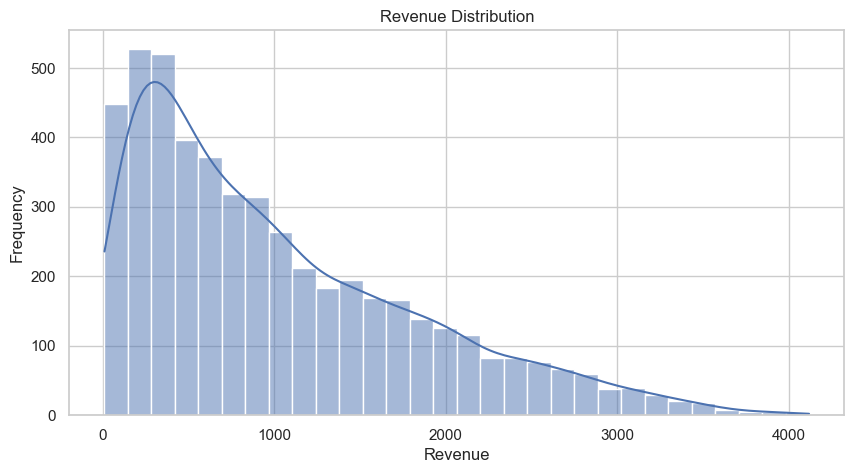

In [3]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df["revenue"],
    bins=30,
    kde=True
)

plt.title("Revenue Distribution")
plt.xlabel("Revenue")
plt.ylabel("Frequency")

plt.show()

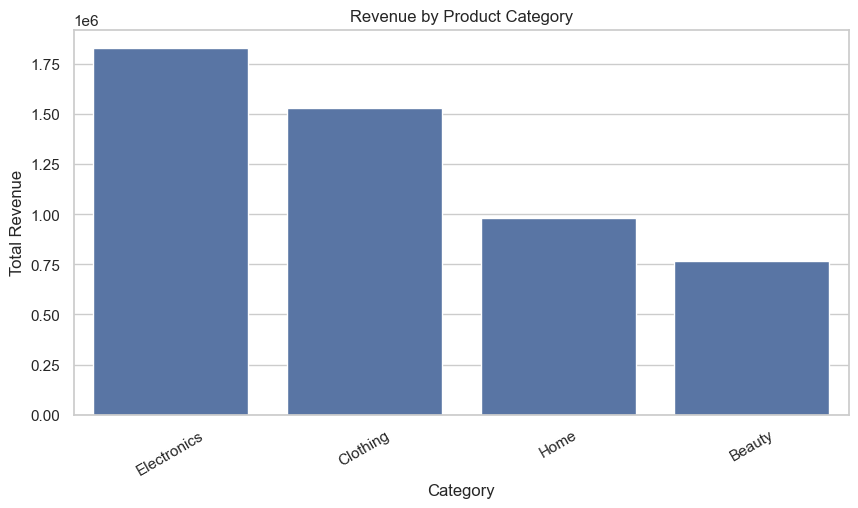

In [4]:
plt.figure(figsize=(10, 5))

category_sales = df.groupby(
    "product_category"
)["revenue"].sum().sort_values(ascending=False)

sns.barplot(
    x=category_sales.index,
    y=category_sales.values
)

plt.title("Revenue by Product Category")
plt.xlabel("Category")
plt.ylabel("Total Revenue")
plt.xticks(rotation=30)

plt.show()

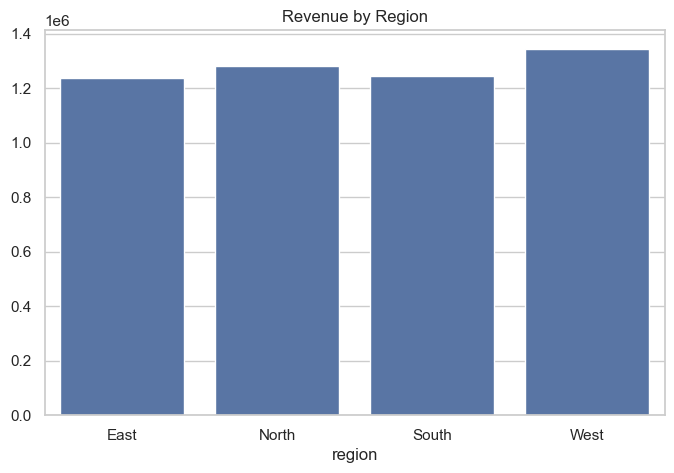

In [5]:
plt.figure(figsize=(8, 5))

region_sales = df.groupby(
    "region"
)["revenue"].sum()

sns.barplot(
    x=region_sales.index,
    y=region_sales.values
)

plt.title("Revenue by Region")

plt.show()

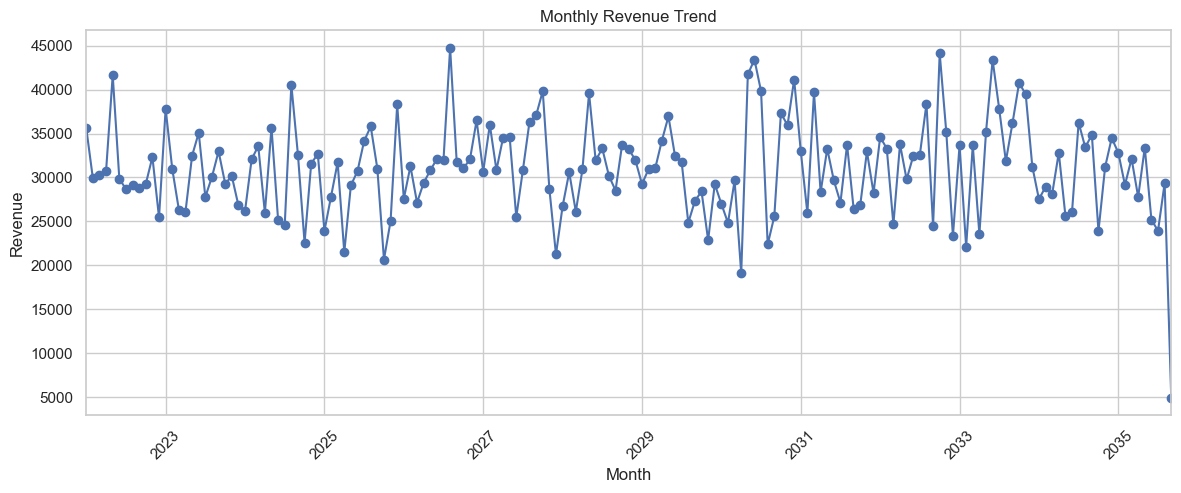

In [6]:
df["month"] = df["order_date"].dt.to_period("M")

monthly_sales = df.groupby(
    "month"
)["revenue"].sum()

plt.figure(figsize=(14, 5))

monthly_sales.plot(
    kind="line",
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")

plt.xticks(rotation=45)

plt.show()

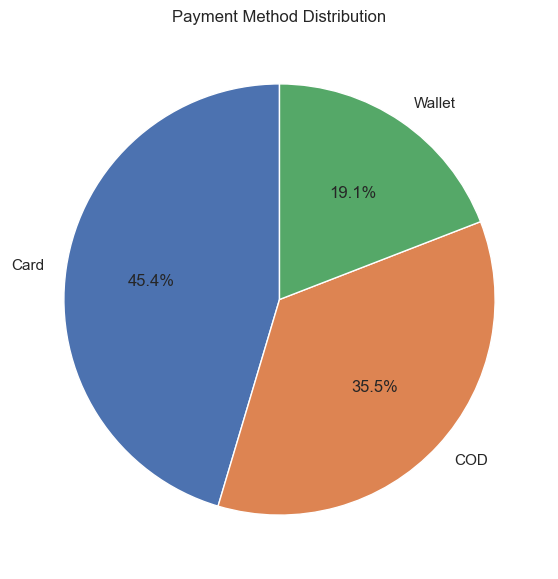

In [7]:
payment = df["payment_method"].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    payment.values,
    labels=payment.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Payment Method Distribution")

plt.show()

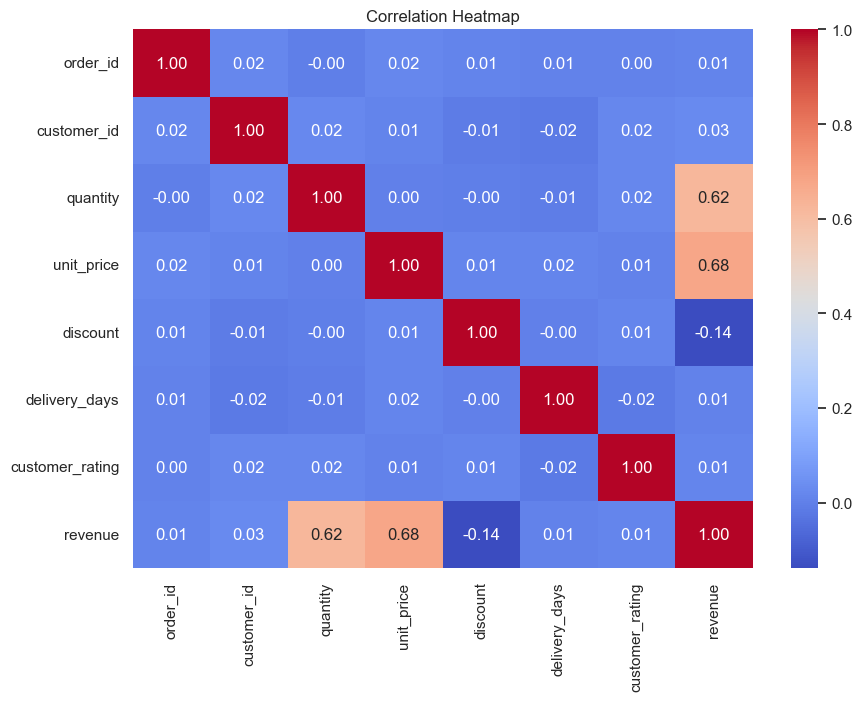

In [8]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    df.select_dtypes(include="number").corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

In [9]:
category_analysis = df.groupby(
    "product_category"
).agg(
    Total_Revenue=("revenue", "sum"),
    Average_Revenue=("revenue", "mean"),
    Total_Quantity=("quantity", "sum"),
    Average_Rating=("customer_rating", "mean")
)

display(category_analysis)

,Total_Revenue,Average_Revenue,Total_Quantity,Average_Rating
product_category,,,,
Beauty,765860.88,1059.281992,2995,3.008990
Clothing,1531931.72,1000.608570,6171,3.005095
Electronics,1829899.22,1029.768835,7109,2.951097
Home,982083.92,1013.502497,3949,2.940660


In [10]:
print(
    "Top Category:",
    df.groupby("product_category")["revenue"]
      .sum().idxmax()
)

print(
    "Top Region:",
    df.groupby("region")["revenue"]
      .sum().idxmax()
)

print(
    "Most Used Payment Method:",
    df["payment_method"].value_counts().idxmax()
)

Top Category: Electronics
Top Region: West
Most Used Payment Method: Card
